# E- handelsanalyysis

## Project syfte

Analysera försäljningsdata for att idetentifera använbara mönster och ge ledgning beslut innan nästa kampanjperiod.

## Frågeställningar

1. Vilka produkt kategorier driver mest intäkt?
2. Vilka städer står för störst intäkt?
3. Hur ser ut Försaljningen över tid?
4. Hur ser en typisk order ut? – AOV (Average Order Value) och spridning.
5. Topp-listor – topp-3 kategorier efter intäkt.
6. Finns det avvikelser eller något oväntat mönster i data?



In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.append("..")

In [7]:
import os

project_root = os.path.abspath("..")
print(project_root)
print(os.listdir(project_root))

c:\Users\suhaa\Desktop\Group_project
['.git', '.gitignore', '.venv', 'data', 'notebooks', 'README.md', 'requirements.txt', 'src']


In [8]:
import sys
sys.path.append("..")

from src.io_utils import load_data

df = pd.read_csv("../data/ecommerce_sales.csv")

print("Data loaded")


Data loaded


In [9]:
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [10]:
print("Ecommerce data Information")
df.info()


Ecommerce data Information
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [11]:
print("Statistics")

print(df.describe())
print()

Statistics
           order_id        price        units      revenue
count    2500.00000  2500.000000  2500.000000  2500.000000
mean   101249.50000   476.213212     2.985200  1401.106892
std       721.83216   312.968413     1.429755  1166.944967
min    100000.00000    50.000000     1.000000    50.000000
25%    100624.75000   254.960000     2.000000   577.960000
50%    101249.50000   413.045000     3.000000  1088.690000
75%    101874.25000   624.427500     4.000000  1884.750000
max    102499.00000  2092.530000     9.000000  9192.600000



In [12]:

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date:" "From", df["date"] . min() , "to" ,df["date"].max())

Date:From 2024-01-01 00:00:00 to 2024-06-30 00:00:00


In [13]:
print("Cities:" ,list(df["city"].unique()))
print()

print("Produkt Categories:" ,list(df["category"].unique()))
print()

Cities: ['Stockholm', 'Malmö', 'Uppsala', 'Göteborg', 'Västerås']

Produkt Categories: ['Sports', 'Clothing', 'Home', 'Electronics', 'Toys', 'Beauty']



## Beräkna total Intäkten

In [14]:
#Total intäkt och Antal enheter

total_intäkt = df["revenue"].sum()
print(f"Total intäkt: {total_intäkt:,.2f} kr")
print()

antal_enheter = df["units"].sum()
print(f"Total antal enheter: {antal_enheter}")


Total intäkt: 3,502,767.23 kr

Total antal enheter: 7463


## Intäkt per stad

In [15]:
#Intäkt Per Stad

#Tabell
import importlib
import src.metrics as metrics

stads_intäkt = metrics.intäkt_per_stad(df)

stads_intäkt_tabell = stads_intäkt.reset_index()
stads_intäkt_tabell.columns = ["Stad" , "Total intäkt"]

display(stads_intäkt_tabell)



,Stad,Total intäkt
0,Stockholm,1227201.94
1,Göteborg,859019.65
2,Malmö,567926.32
3,Uppsala,551478.42
4,Västerås,297140.90


In [16]:
högst_intäkt_stad = stads_intäkt.idxmax()
hogsta_stads_intakt = stads_intäkt.max()

print(f"Stad med högst intäkt: {högst_intäkt_stad}")
print(f"Högsta stads intäkten: {hogsta_stads_intakt:,.2f} kr")

Stad med högst intäkt: Stockholm
Högsta stads intäkten: 1,227,201.94 kr


In [17]:
# kategori intäkt 

In [18]:
# Top tre kategori

In [19]:
# månads intäkt

In [20]:
#aov

In [21]:
#ordervalue distribution


import importlib
import src.metrics as metrics

importlib.reload(metrics)

order_values = metrics.ordervarden(df)

print("Antal unika orderr:", order_values.size)
print(f"Lägsta ordervärde: {order_values.min():,.2f} kr")
print(f"Median för ordervärde: {order_values.median():,.2f} kr")
print(f"Högsta ordervärde: {order_values.max():,.2f} kr")

Antal unika orderr: 2500
Lägsta ordervärde: 50.00 kr
Median för ordervärde: 1,088.69 kr
Högsta ordervärde: 9,192.60 kr


In [22]:
nyckeltal_tabell = pd.DataFrame({
    "Nyckeltal": [
        "Total intäkt",
        "Totalt antal sålda enheter",
        "Antal unika ordrar",
        "Stad med högst intäkt",
    ],
    "Resultat": [
        f"{total_intäkt:,.2f} kr",
        f"{antal_enheter:,}",
        f"{order_values.size:,}",
        str(stads_intäkt.idxmax()),
        
    ]
})

display(nyckeltal_tabell)


,Nyckeltal,Resultat
0,Total intäkt,"3,502,767.23 kr"
1,Totalt antal sålda enheter,"7,463"
2,Antal unika ordrar,"2,500"
3,Stad med högst intäkt,Stockholm


# Visualization

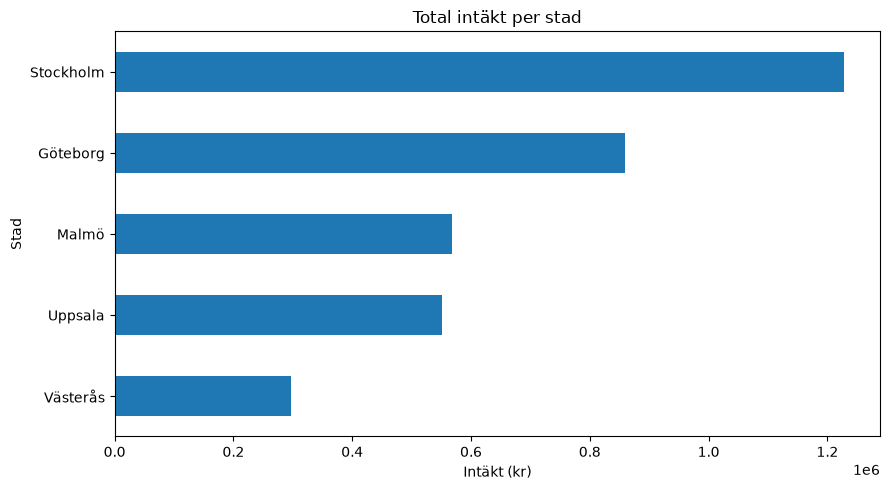

In [23]:
#plot intäkt per stad

import importlib
import src.viz as viz

importlib.reload(viz)

viz.plot_intakt_per_stad(stads_intäkt)

In [24]:
#plot kategory

In [25]:
#plot topp tre kategori

In [26]:
#plot försäjlning over tid

In [27]:
#Aov

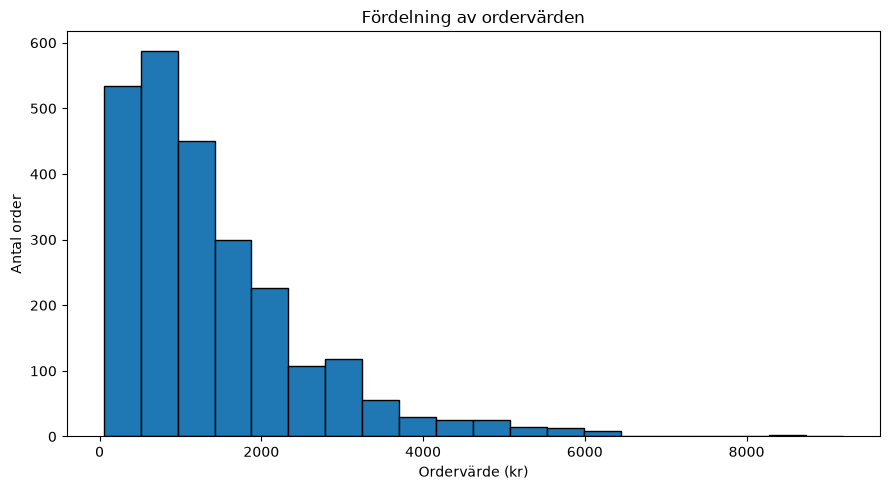

In [28]:
#order value distributin


import importlib
import src.viz as viz

importlib.reload(viz)

viz.plot_ordervarden(order_values)

## Analysera  avvikelser och något oväntat mönster


In [29]:
# Saknande värden per kolumn
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Invalid or unusual values
print("Price <= 0:", (df["price"] <= 0).sum())
print("Units <= 0:", (df["units"] <= 0).sum())
print("Revenue < 0:", (df["revenue"] < 0).sum())

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Duplicate rows: 0
Price <= 0: 0
Units <= 0: 0
Revenue < 0: 0


In [30]:

import numpy as np
import pandas as pd

kolumner = ["price", "units", "revenue"]

sammanfattningar = []
outlier_limit = {}
outlier_data = {}

for kolumn in kolumner:
    values = df[kolumn].dropna().to_numpy()

    minimum = np.min(values)
    q1 = np.percentile(values, 25)
    median = np.median(values)
    q3 = np.percentile(values, 75)
    maximum = np.max(values)

    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Identifiera potentiella avvikande värden
    mask = (df[kolumn] < lower_limit) | (
        df[kolumn] > upper_limit
    )
    avvikelser = df.loc[mask]

    sammanfattningar.append({
        "Kolumn": kolumn,
        "Minimum": minimum,
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "Maximum": maximum,
        "IQR": iqr,
        "Antal avvikelser": len(avvikelser)
    })

    outlier_limit[kolumn] = (
        lower_limit, upper_limit
    )
    outlier_data[kolumn] = avvikelser

sammanfattning = pd.DataFrame(sammanfattningar)

display(sammanfattning.round(2))


,Kolumn,Minimum,Q1,Median,Q3,Maximum,IQR,Antal avvikelser
0,price,50.0,254.96,413.04,624.43,2092.53,369.47,88
1,units,1.0,2.00,3.00,4.00,9.00,2.00,7
2,revenue,50.0,577.96,1088.69,1884.75,9192.60,1306.79,111


In [31]:
alla_avvikelser = pd.concat(
    [outlier_data[kolumn] for kolumn in kolumner]
).drop_duplicates()

print(f"Totalt antal unika rader med avvikelser: {len(alla_avvikelser)}")

display(
    alla_avvikelser[
        ["order_id", "date", "city",
         "category", "price", "units", "revenue"]
    ].sort_values("revenue", ascending=False)
)


Totalt antal unika rader med avvikelser: 162


,order_id,date,city,category,price,units,revenue
1411,101411,2024-02-26,Stockholm,Electronics,1838.52,5,9192.60
1339,101339,2024-02-26,Göteborg,Electronics,1703.37,5,8516.85
1491,101491,2024-06-04,Västerås,Electronics,2092.53,4,8370.12
1733,101733,2024-06-05,Uppsala,Electronics,1227.73,6,7366.38
1518,101518,2024-01-12,Göteborg,Electronics,1403.69,5,7018.45
...,...,...,...,...,...,...,...
1533,101533,2024-05-10,Västerås,Electronics,1264.50,1,1264.50
223,100223,2024-04-09,Malmö,Electronics,1257.95,1,1257.95
1408,101408,2024-04-20,Uppsala,Electronics,1236.04,1,1236.04
1722,101722,2024-06-27,Stockholm,Electronics,1222.72,1,1222.72


Datasetet innehåller 2 500 rader och 7 kolumner. Vi hittade inga saknade värden eller dubblettrader. Det fanns inte heller några negativa värden i kolumnerna price, units eller revenue.

Vi använde femtals-sammanfattningen och IQR-metoden för att identifiera potentiellt avvikande värden. Analysen visade 88 avvikande värden i price, 7 i units och 111 i revenue.

Resultaten visar att kategorin Electronics har flest avvikande värden, både för pris och intäkt. Detta kan bero på att elektronikprodukter ofta har högre priser och att försäljning av flera enheter kan ge högre intäkter.